<a href="https://colab.research.google.com/github/arif18-tech/TinyML/blob/main/TinyML_04_CNN.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

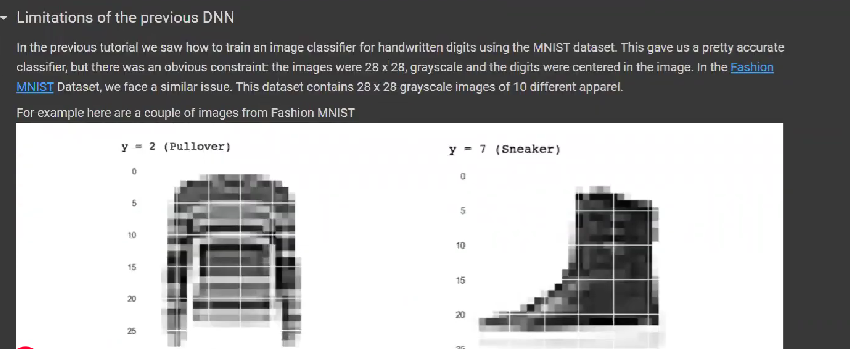

In [1]:
import cv2
import tensorflow as tf
import numpy as np
from tensorflow import keras
import matplotlib.pyplot as plt
from scipy import datasets

i = datasets.ascent()

Source image

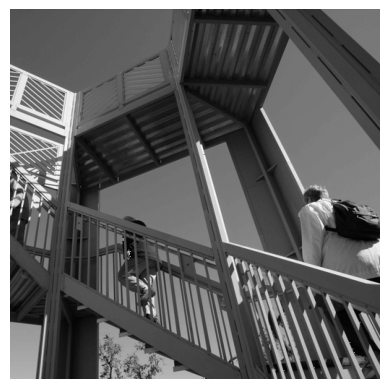

In [2]:
plt.grid(False)
plt.gray()
plt.axis('off')
plt.imshow(i)
plt.show()

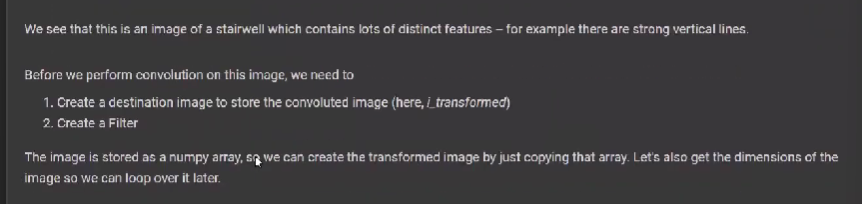

In [3]:
i_transformed = np.copy(i)
size_x=i_transformed.shape[0]
size_y=i_transformed.shape[1]

In [ ]:
#this filler detects edges nicely
#it It creates a convolution that only passes through sharp edges and straight # lines.
# Lxperiment with different values for fun effects.
#filler [[0, 1, 0], [1, -4, 1], [0, 1, 0]]
#A couple more filters to try for fun!
Filter = [[-1, -2, -1], [0, 0, 0], [1, 2, 1]]
#filter[[-1, 0, 1], [2] 6, 7], [-1, 0, 1]]
# It all the digits in the filter don't add up to a or 1, you
#should probably do a weight to get it to do so
#forexample, if your weights are 1,1,1 1,2,1 1,1,1
#They add up to 18, so you would set a weight of 1 if you want to normalize them
weight =1

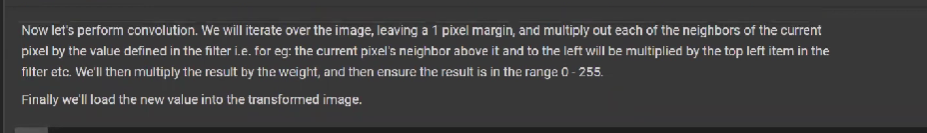

In [4]:
i_transformed = np.copy(i)
size_x = i_transformed.shape[0]
size_y = i_transformed.shape[1]

# Using lowercase filter to match the code below
filter = [[-1, -2, -1], [0, 0, 0], [1, 2, 1]]
weight = 1

for x in range(1, size_x - 1):
    for y in range(1, size_y - 1):
        convolution = 0.0
        # Casting the uint8 pixel values to float prevents the OverflowError
        convolution = convolution + (float(i[x-1, y-1]) * filter[0][0])
        convolution = convolution + (float(i[x, y-1]) * filter[1][0])
        convolution = convolution + (float(i[x+1, y-1]) * filter[2][0])
        convolution = convolution + (float(i[x-1, y]) * filter[0][1])
        convolution = convolution + (float(i[x, y]) * filter[1][1])
        convolution = convolution + (float(i[x+1, y]) * filter[2][1])
        convolution = convolution + (float(i[x-1, y+1]) * filter[0][2])
        convolution = convolution + (float(i[x, y+1]) * filter[1][2])
        convolution = convolution + (float(i[x+1, y+1]) * filter[2][2])
        convolution = convolution * weight
        if convolution < 0:
            convolution = 0
        if convolution > 255:
            convolution = 255
        i_transformed[x, y] = convolution

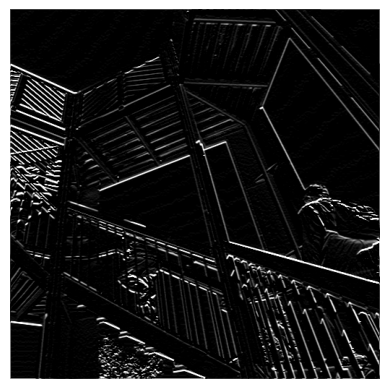

In [5]:
# Plot the transformed image to see the results of the convolution
plt.grid(False)
plt.gray()
plt.axis('off')
plt.imshow(i_transformed)
plt.show()

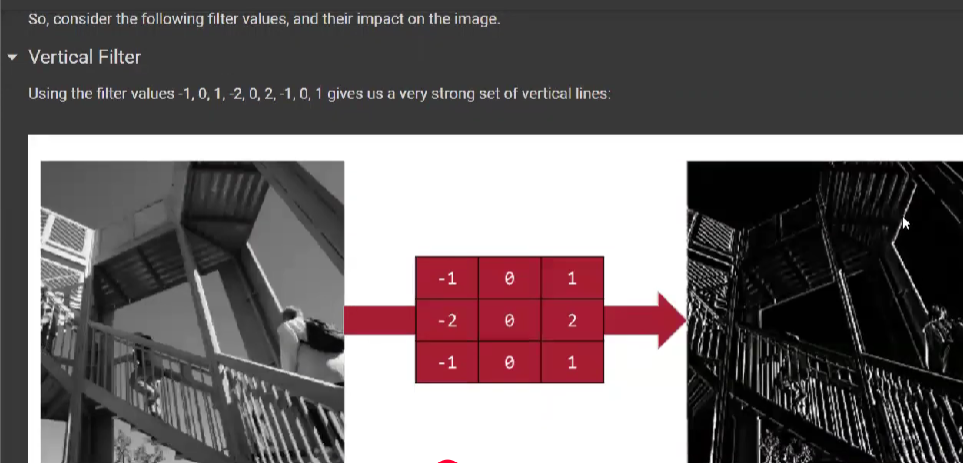

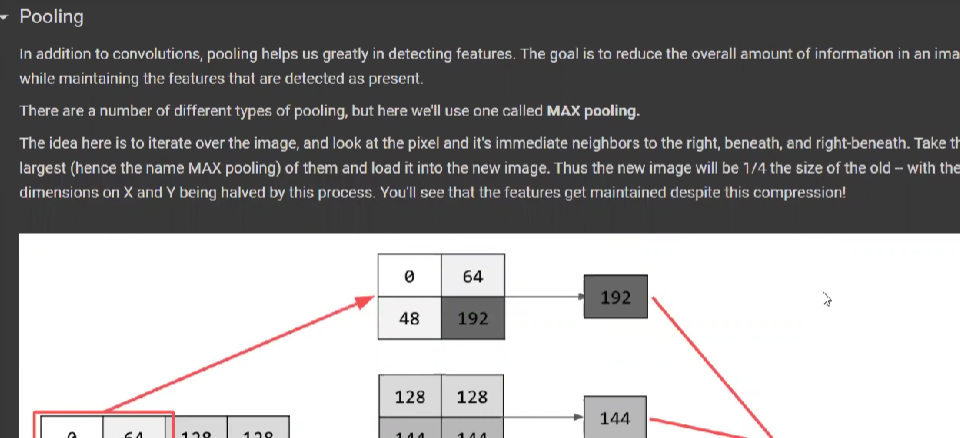

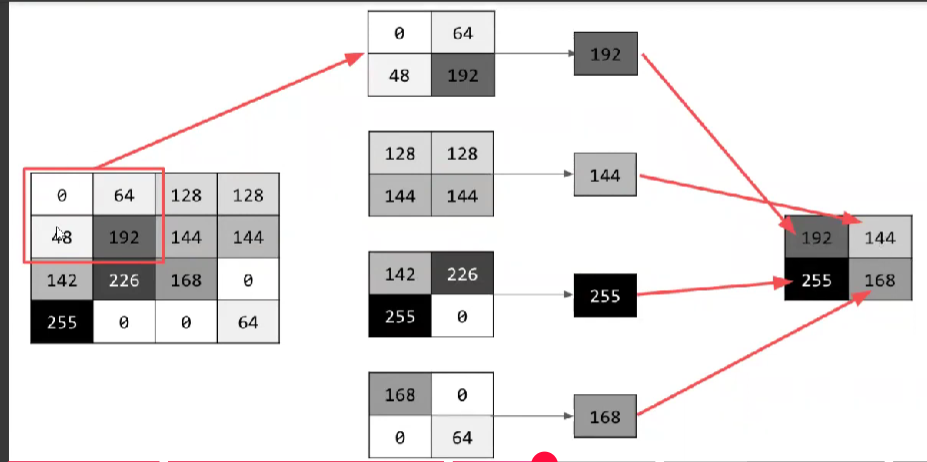

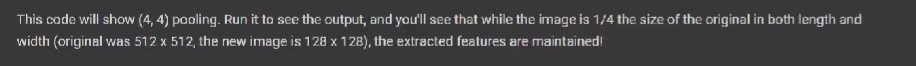

In [6]:
new_x = int(size_x/4)
new_y = int(size_y/4)
newimage = np.zeros((new_x, new_y))
for x in range(0, size_x, 4):
  for y in range(0, size_y, 4):
    pixels = []
    pixels.append(i_transformed[x, y])
    pixels.append(i_transformed[x+1, y])
    pixels.append(i_transformed[x+2, y])
    pixels.append(i_transformed[x+3, y])
    pixels.append(i_transformed[x, y+1])
    pixels.append(i_transformed [x + 1, y + 1 ])
    pixels.append(i_transformed [x + 2, y + 1] )
    pixels.append(i_transformed [x+3, y+1])
    pixels.append(i_transformed [x, y + 2])
    pixels.append(i_transformed [ x + 1 ,y+2])
    pixels.append(i_transformed [x + 2, y + 2 ])
    pixels.append(i_transformed[x+3, y+2])
    pixels.append(i_transformed [x, y + 3] )
    pixels.append(i_transformed[x+1, y+3])
    pixels.append(i_transformed [x + 2, y + 3 ])
    pixels.append(i_transformed [x + 3, y + 3 ])
    pixels.sort(reverse = True)
    newimage[int(x/4), int(y/4)] = pixels[0]

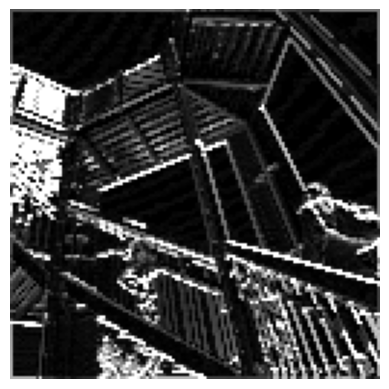

In [7]:
# Plot the transformed image to see the results of the convolution
plt.grid(False)
plt.gray()
plt.axis('off')
plt.imshow(newimage)
plt.show()

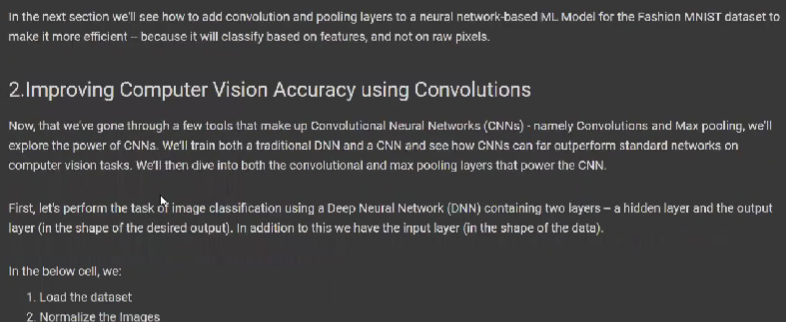

In [ ]:
mnist = tf.keras.datasets.mnist
(training_images, training_labels), (val_images, val_labels) = mnist.load_data()

# normalize images
training_images = training_images / 255.0
val_images = val_images / 255.0

# define model
model = tf.keras.models.Sequential([
  tf.keras.layers.Flatten(),
  tf.keras.layers.Dense(20, activation=tf.nn.relu),
  tf.keras.layers.Dense(10, activation=tf.nn.softmax)
])

model.compile(optimizer='adam', loss='sparse_categorical_crossentropy', metrics=['accuracy'])

# train model
print()
print("Training Model!")
model.fit(training_images, training_labels, validation_data=(val_images, val_labels), epochs=20)

11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step

Training Model!
Epoch 1/20
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 9s 4ms/step - accuracy: 0.8851 - loss: 0.4125 - val_accuracy: 0.9286 - val_loss: 0.2397
Epoch 2/20
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 6s 3ms/step - accuracy: 0.9359 - loss: 0.2223 - val_accuracy: 0.9387 - val_loss: 0.2037
Epoch 3/20
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 6s 3ms/step - accuracy: 0.9450 - loss: 0.1874 - val_accuracy: 0.9453 - val_loss: 0.1823
Epoch 4/20
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 6s 3ms/step - accuracy: 0.9532 - loss: 0.1650 - val_accuracy: 0.9501 - val_loss: 0.1634
Epoch 5/20
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 5s 3ms/step - accuracy: 0.9564 - loss: 0.1501 - val_accuracy: 0.9508 - val_loss: 0.1606
Epoch 6/20
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 5s 3ms/step - accuracy: 0.9601 - loss: 0.1382 - val_accuracy: 0.9502 - val_loss: 0.1600
Epoch 7/20
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 5s 3ms/step - accuracy: 0.9626 - loss: 0.1299 - val_accuracy: 0.9540 - val_loss: 0.1534
Epoch 8/20
1875/1875 ━

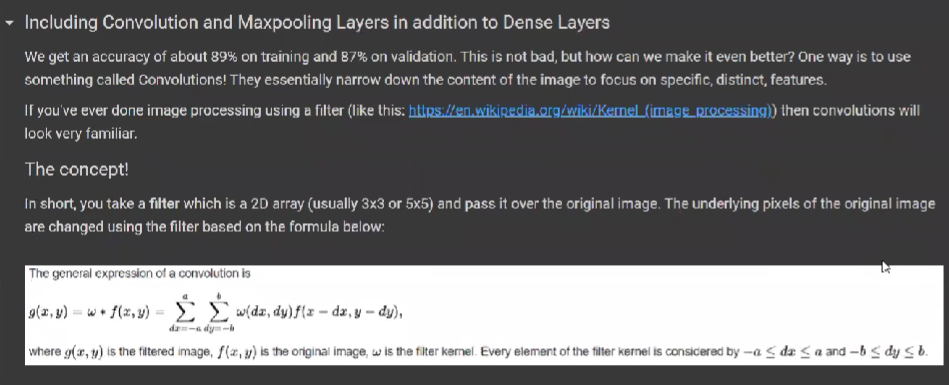

In [8]:
mnist = tf.keras.datasets.mnist
(training_images, training_labels), (val_images, val_labels) = mnist.load_data()

#reshape
training_images = training_images.reshape(60000, 28, 28, 1)
val_images = val_images.reshape(10000, 28, 28, 1)

# normalize images
training_images = training_images / 255.0
val_images = val_images / 255.0

11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


In [9]:
model=tf.keras.models.Sequential([
    tf.keras.layers.Conv2D(64, (3,3), activation='relu', input_shape=(28,28,1)),
    tf.keras.layers.MaxPooling2D(2,2),
    tf.keras.layers.Conv2D(64, (3,3), activation='relu'),
    tf.keras.layers.MaxPooling2D(2,2),
    tf.keras.layers.Flatten(),
    tf.keras.layers.Dense(128, activation='relu'),
    tf.keras.layers.Dense(10, activation='softmax')
])
model.compile(optimizer='adam', loss='sparse_categorical_crossentropy', metrics=['accuracy'])

/usr/local/lib/python3.13/dist-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


In [ ]:
model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 26, 26, 64)     │           640 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 13, 13, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 11, 11, 64)     │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 5, 5, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_1 (Flatten)             │ (None, 1600)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 128)            │       204,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 243,786 (952.29 KB)

 Trainable params: 243,786 (952.29 KB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
model.fit(training_images, training_labels, epochs=20, validation_data= (val_images, val_labels))

Epoch 1/20
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 17s 6ms/step - accuracy: 0.9626 - loss: 0.1222 - val_accuracy: 0.9882 - val_loss: 0.0390
Epoch 2/20
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 7s 4ms/step - accuracy: 0.9872 - loss: 0.0416 - val_accuracy: 0.9909 - val_loss: 0.0300
Epoch 3/20
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 7s 4ms/step - accuracy: 0.9913 - loss: 0.0282 - val_accuracy: 0.9906 - val_loss: 0.0280
Epoch 4/20
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 8s 4ms/step - accuracy: 0.9936 - loss: 0.0196 - val_accuracy: 0.9908 - val_loss: 0.0300
Epoch 5/20
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 7s 4ms/step - accuracy: 0.9952 - loss: 0.0153 - val_accuracy: 0.9895 - val_loss: 0.0336
Epoch 6/20
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 8s 4ms/step - accuracy: 0.9963 - loss: 0.0113 - val_accuracy: 0.9896 - val_loss: 0.0351
Epoch 7/20
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 7s 4ms/step - accuracy: 0.9962 - loss: 0.0109 - val_accuracy: 0.9930 - val_loss: 0.0317
Epoch 8/20
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 8s 4ms/step - accuracy: 0.9975 - loss: 0.0078 -

In [10]:
print ([(x, val_labels[x]) for x in range(100)])

[(0, np.uint8(7)), (1, np.uint8(2)), (2, np.uint8(1)), (3, np.uint8(0)), (4, np.uint8(4)), (5, np.uint8(1)), (6, np.uint8(4)), (7, np.uint8(9)), (8, np.uint8(5)), (9, np.uint8(9)), (10, np.uint8(0)), (11, np.uint8(6)), (12, np.uint8(9)), (13, np.uint8(0)), (14, np.uint8(1)), (15, np.uint8(5)), (16, np.uint8(9)), (17, np.uint8(7)), (18, np.uint8(3)), (19, np.uint8(4)), (20, np.uint8(9)), (21, np.uint8(6)), (22, np.uint8(6)), (23, np.uint8(5)), (24, np.uint8(4)), (25, np.uint8(0)), (26, np.uint8(7)), (27, np.uint8(4)), (28, np.uint8(0)), (29, np.uint8(1)), (30, np.uint8(3)), (31, np.uint8(1)), (32, np.uint8(3)), (33, np.uint8(4)), (34, np.uint8(7)), (35, np.uint8(2)), (36, np.uint8(7)), (37, np.uint8(1)), (38, np.uint8(2)), (39, np.uint8(1)), (40, np.uint8(1)), (41, np.uint8(7)), (42, np.uint8(4)), (43, np.uint8(2)), (44, np.uint8(3)), (45, np.uint8(5)), (46, np.uint8(1)), (47, np.uint8(2)), (48, np.uint8(4)), (49, np.uint8(4)), (50, np.uint8(6)), (51, np.uint8(3)), (52, np.uint8(5)), (5

In [12]:
def show_images(imag):
  plt.figure()
  plt.imshow(val_images[imag].reshape(28,28))

  plt.grid(False)
  plt.show()

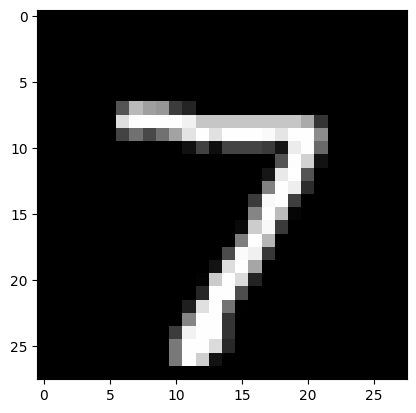

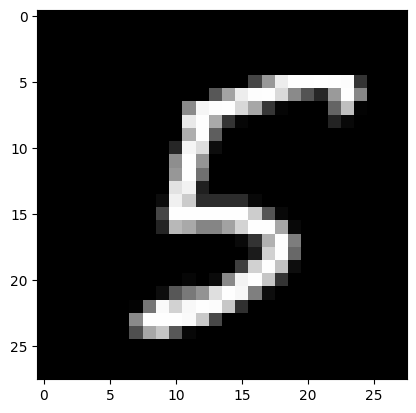

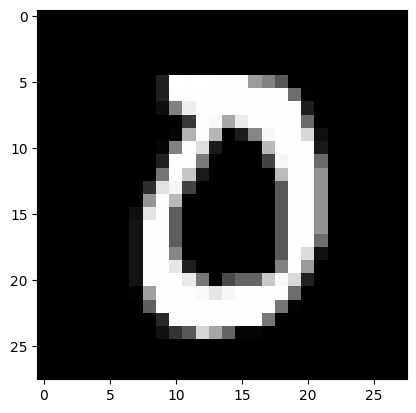

In [13]:
FIRST_IMAGE=0
SECOND_IMAGE=23
THIRD_IMAGE=28
show_images(FIRST_IMAGE)
show_images(SECOND_IMAGE)
show_images(THIRD_IMAGE)
